In [136]:
#!pip install openpyxl

In [137]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
pd.set_option('display.max_columns', None)

In [138]:
df=pd.read_excel("Autism child data.xlsx")
df.head()

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jundice,austim,contry_of_res,used_app_before,result,age_desc,relation,Class/ASD
0,1,1,0,0,1,1,0,1,0,0,6,m,Others,no,no,Jordan,no,5,4-11 years,Parent,NO
1,1,1,0,0,1,1,0,1,0,0,6,m,Middle Eastern,no,no,Jordan,no,5,4-11 years,Parent,NO
2,1,1,1,1,1,1,1,1,1,1,5,m,Others,yes,no,United States,no,10,4-11 years,Parent,YES
3,1,0,1,1,1,1,0,1,0,1,5,m,White-European,no,no,United Kingdom,no,7,4-11 years,Parent,YES
4,1,1,1,1,1,1,1,1,0,0,5,f,Middle Eastern,no,no,Bahrain,no,8,4-11 years,Parent,YES


In [139]:
df.isnull().sum()

A1_Score           0
A2_Score           0
A3_Score           0
A4_Score           0
A5_Score           0
A6_Score           0
A7_Score           0
A8_Score           0
A9_Score           0
A10_Score          0
age                0
gender             0
ethnicity          0
jundice            0
austim             0
contry_of_res      0
used_app_before    0
result             0
age_desc           0
relation           0
Class/ASD          0
dtype: int64

In [140]:
df.describe()

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,result
count,498.000000,498.000000,498.000000,498.000000,498.000000,498.000000,498.000000,498.000000,498.000000,498.000000,498.000000
mean,0.682731,0.514056,0.746988,0.570281,0.751004,0.710843,0.622490,0.477912,0.542169,0.730924,6.345382
std,0.465881,0.500305,0.435175,0.495534,0.432866,0.453827,0.485252,0.500014,0.502738,0.443926,2.360214
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000
50%,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,7.000000
75%,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,8.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000,10.000000


In [141]:
df.shape

(498, 21)

In [142]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 498 entries, 0 to 497
Data columns (total 21 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   A1_Score         498 non-null    int64 
 1   A2_Score         498 non-null    int64 
 2   A3_Score         498 non-null    int64 
 3   A4_Score         498 non-null    int64 
 4   A5_Score         498 non-null    int64 
 5   A6_Score         498 non-null    int64 
 6   A7_Score         498 non-null    int64 
 7   A8_Score         498 non-null    int64 
 8   A9_Score         498 non-null    int64 
 9   A10_Score        498 non-null    int64 
 10  age              498 non-null    object
 11  gender           498 non-null    object
 12  ethnicity        498 non-null    object
 13  jundice          498 non-null    object
 14  austim           498 non-null    object
 15  contry_of_res    498 non-null    object
 16  used_app_before  498 non-null    object
 17  result           498 non-null    in

In [143]:
df = df.dropna()

In [144]:
df.columns = [ "A1_Score","A2_Score","A3_Score","A4_Score","A5_Score","A6_Score","A7_Score","A8_Score","A9_Score","A10_Score","age","gender","ethnicity","jaundice","autism","country_of_res","used_app_before","result","age_desc","relation","Class_ASD",]
df.head()

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,autism,country_of_res,used_app_before,result,age_desc,relation,Class_ASD
0,1,1,0,0,1,1,0,1,0,0,6,m,Others,no,no,Jordan,no,5,4-11 years,Parent,NO
1,1,1,0,0,1,1,0,1,0,0,6,m,Middle Eastern,no,no,Jordan,no,5,4-11 years,Parent,NO
2,1,1,1,1,1,1,1,1,1,1,5,m,Others,yes,no,United States,no,10,4-11 years,Parent,YES
3,1,0,1,1,1,1,0,1,0,1,5,m,White-European,no,no,United Kingdom,no,7,4-11 years,Parent,YES
4,1,1,1,1,1,1,1,1,0,0,5,f,Middle Eastern,no,no,Bahrain,no,8,4-11 years,Parent,YES


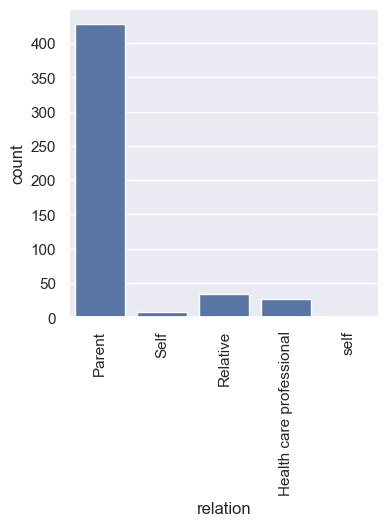

In [145]:
sns.countplot(x='relation',data=df)
plt.xticks(rotation=90)
sns.set(rc={'figure.figsize':(5, 5)})

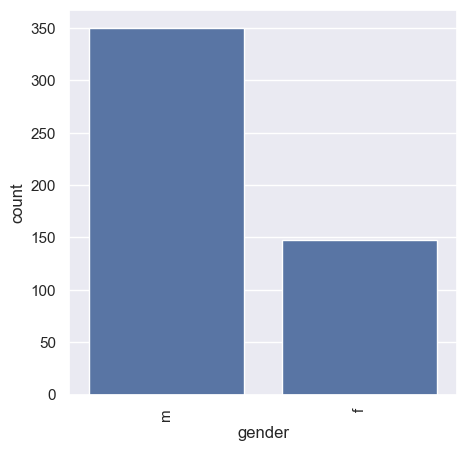

In [146]:
sns.countplot(x='gender',data=df)
plt.xticks(rotation=90)
sns.set(rc={'figure.figsize':(5, 5)})

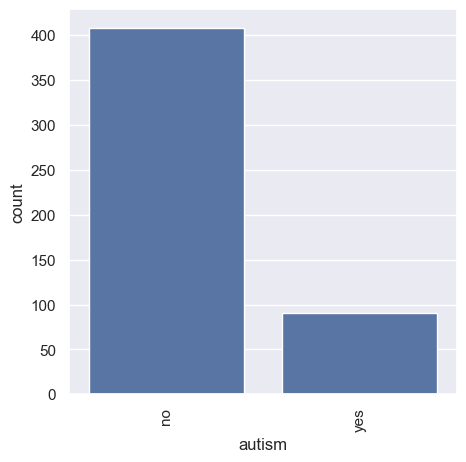

In [147]:
sns.countplot(x='autism',data=df)
plt.xticks(rotation=90)
sns.set(rc={'figure.figsize':(5, 5)})

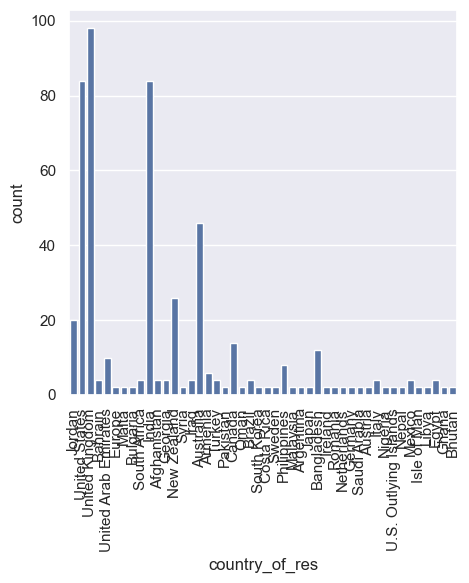

In [148]:
sns.countplot(x='country_of_res',data=df)
plt.xticks(rotation=90)
sns.set(rc={'figure.figsize':(7, 13)})

([0, 1], [Text(0, 0, 'NO'), Text(1, 0, 'YES')])

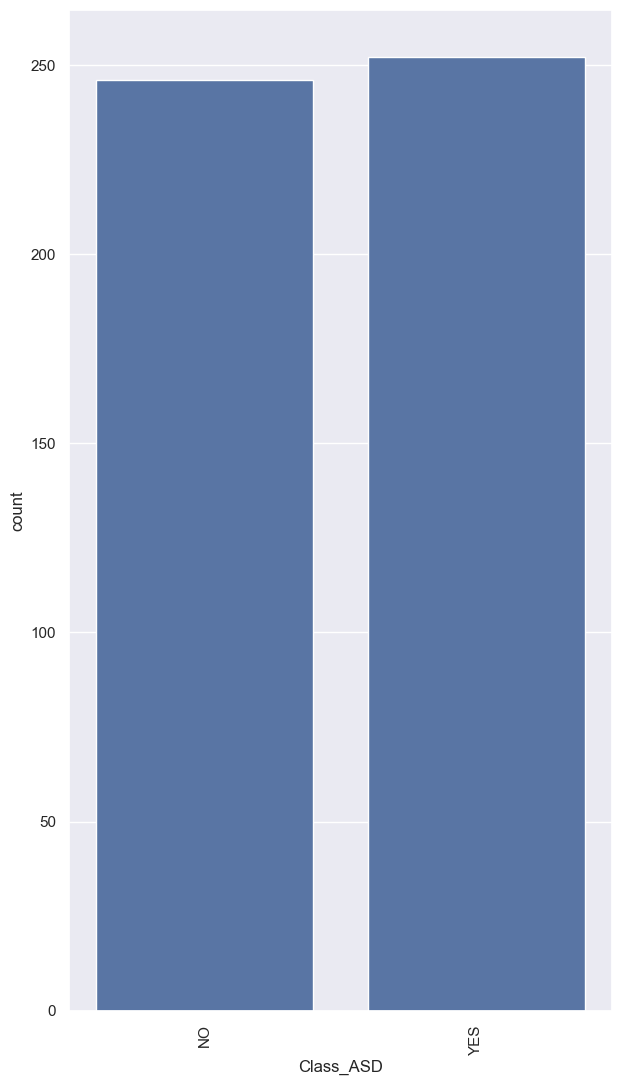

In [149]:
sns.countplot(x='Class_ASD',data=df)
plt.xticks(rotation=90)


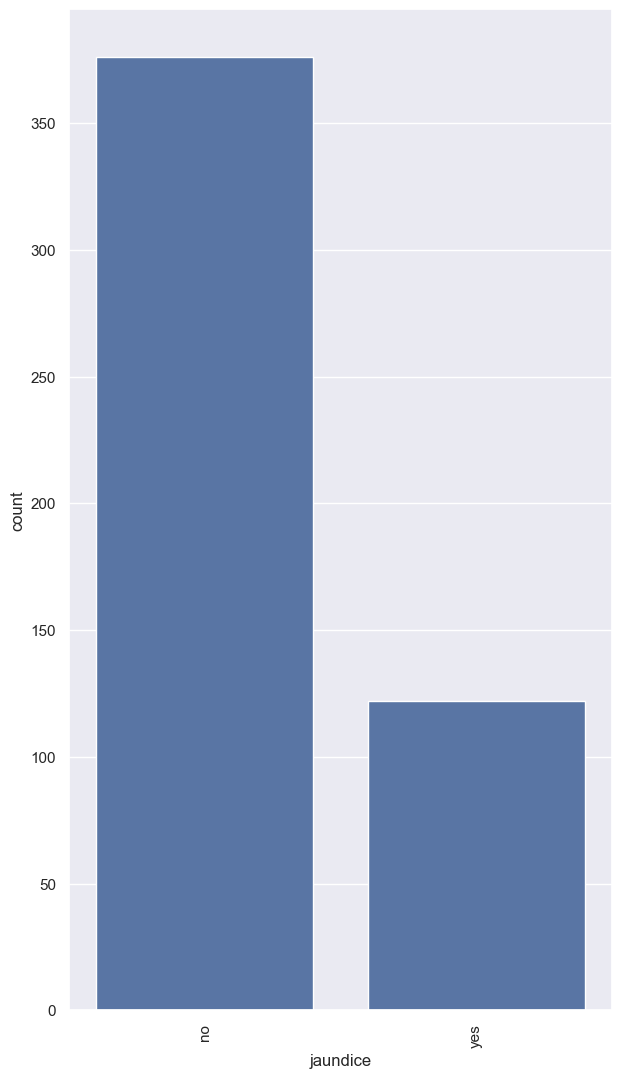

In [150]:
sns.countplot(x='jaundice',data=df)
plt.xticks(rotation=90)
sns.set(rc={'figure.figsize':(4, 4)})

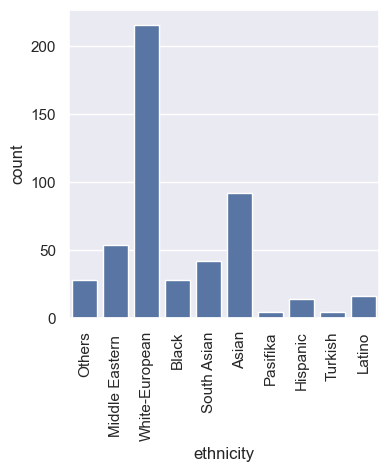

In [151]:
sns.countplot(x='ethnicity',data=df)
plt.xticks(rotation=90)
sns.set(rc={'figure.figsize':(5,5)})

In [152]:
df = df[df['age']!='?']

In [153]:
org_data = df[[ "A1_Score", "A2_Score", "A3_Score", "A4_Score", "A5_Score", "A6_Score", "A7_Score", "A8_Score", "A9_Score", "A10_Score", "age", ]]


In [154]:
label_encoded_data = df[["gender", "autism", "jaundice", "Class_ASD"]]
label_encoded_data["gender"] = label_encoded_data["gender"].apply(lambda x: 1 if x == "m" else 0)
label_encoded_data["autism"] = label_encoded_data["autism"].apply(lambda x: 1 if x == "yes" else 0)
label_encoded_data["jaundice"] = label_encoded_data["jaundice"].apply(lambda x: 1 if x == "yes" else 0)
label_encoded_data["Class_ASD"] = label_encoded_data["Class_ASD"].apply(lambda x: 1 if x == "YES" else 0)
one_hot_encoded_data = df[["ethnicity"]]
one_hot_encoded_data = pd.get_dummies(one_hot_encoded_data)

C:\Users\0945\AppData\Local\Temp\ipykernel_4548\1078309036.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  label_encoded_data["gender"] = label_encoded_data["gender"].apply(lambda x: 1 if x == "m" else 0)
C:\Users\0945\AppData\Local\Temp\ipykernel_4548\1078309036.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  label_encoded_data["autism"] = label_encoded_data["autism"].apply(lambda x: 1 if x == "yes" else 0)
C:\Users\0945\AppData\Local\Temp\ipykernel_4548\1078309036.py:4: SettingWithCopyWarning: 
A 

In [155]:
fixed_data = pd.concat([org_data,label_encoded_data,one_hot_encoded_data],axis=1)

fixed_data.head()

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,autism,jaundice,Class_ASD,ethnicity_Asian,ethnicity_Black,ethnicity_Hispanic,ethnicity_Latino,ethnicity_Middle Eastern,ethnicity_Others,ethnicity_Pasifika,ethnicity_South Asian,ethnicity_Turkish,ethnicity_White-European
0,1,1,0,0,1,1,0,1,0,0,6,1,0,0,0,False,False,False,False,False,True,False,False,False,False
1,1,1,0,0,1,1,0,1,0,0,6,1,0,0,0,False,False,False,False,True,False,False,False,False,False
2,1,1,1,1,1,1,1,1,1,1,5,1,0,1,1,False,False,False,False,False,True,False,False,False,False
3,1,0,1,1,1,1,0,1,0,1,5,1,0,0,1,False,False,False,False,False,False,False,False,False,True
4,1,1,1,1,1,1,1,1,0,0,5,0,0,0,1,False,False,False,False,True,False,False,False,False,False


In [156]:
X = fixed_data.drop(columns=['Class_ASD'])
y = fixed_data[['Class_ASD']]

In [157]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.3, random_state=42)

In [158]:
X_test.shape

(149, 24)

In [159]:
y_train.shape

(347, 1)

In [160]:
lr=LogisticRegression()
lr.fit(X_train,y_train)

C:\Users\0945\AppData\Roaming\Python\Python310\site-packages\sklearn\utils\validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


LogisticRegression()

In [161]:
y_pred=lr.predict(X_test)

In [162]:
lraccuracy=accuracy_score(y_test, y_pred)
lraccuracy

0.9865771812080537

In [163]:
RF=RandomForestClassifier(n_estimators=1000, max_depth=None, min_samples_split=2, random_state=0)
RF.fit(X_train,y_train)

C:\Users\0945\AppData\Roaming\Python\Python310\site-packages\sklearn\base.py:1473: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


RandomForestClassifier(n_estimators=1000, random_state=0)

In [164]:
y_pred=RF.predict(X_test)
RFaccuracy=accuracy_score(y_test, y_pred)
RFaccuracy

0.9865771812080537

In [165]:
DT=DecisionTreeClassifier(max_depth=None, min_samples_split=2, random_state=0)
DT.fit(X_train,y_train)

DecisionTreeClassifier(random_state=0)

In [166]:
y_pred=DT.predict(X_test)
DTaccuracy=accuracy_score(y_test, y_pred)
DTaccuracy

0.9731543624161074

In [167]:
svc=SVC(kernel='linear')
svc.fit(X_train,y_train)

C:\Users\0945\AppData\Roaming\Python\Python310\site-packages\sklearn\utils\validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVC(kernel='linear')

In [168]:
y_pred=svc.predict(X_test)
svcaccuracy=accuracy_score(y_test, y_pred)
svcaccuracy

1.0

In [169]:
svc.predict([[1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1]])

C:\Users\0945\AppData\Roaming\Python\Python310\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


array([1], dtype=int64)

In [170]:
lr.predict([[1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1]])

C:\Users\0945\AppData\Roaming\Python\Python310\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0], dtype=int64)

In [171]:
data=pd.DataFrame({"Algorithm":['SUPPORT VECTOR MACHINE','LOGISTIC REGRESSION', 'RANDOM FOREST', 'DECISION TREE'],
                 "Accuracy":[svcaccuracy, lraccuracy, RFaccuracy, DTaccuracy]})

In [172]:
data

,Algorithm,Accuracy
0,SUPPORT VECTOR MACHINE,1.000000
1,LOGISTIC REGRESSION,0.986577
2,RANDOM FOREST,0.986577
3,DECISION TREE,0.973154


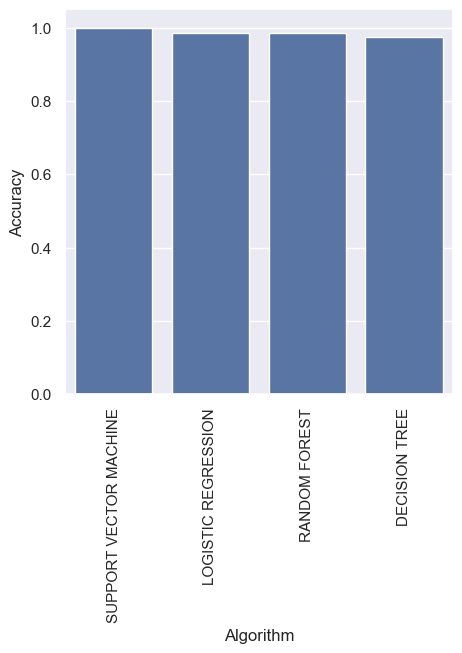

In [173]:
x = data['Algorithm']
y = data['Accuracy']
sns.barplot(x=x, y=y, data=data)
plt.xticks(rotation=90)
sns.set(rc={'figure.figsize': (4, 4)})


In [174]:
#=================================== D.L Algorithms =====================================

## ANN

In [175]:
X_train

,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,autism,jaundice,ethnicity_Asian,ethnicity_Black,ethnicity_Hispanic,ethnicity_Latino,ethnicity_Middle Eastern,ethnicity_Others,ethnicity_Pasifika,ethnicity_South Asian,ethnicity_Turkish,ethnicity_White-European
16,1,0,1,1,0,1,0,0,1,0,6,0,0,0,False,False,False,False,False,False,False,True,False,False
484,1,0,0,0,1,0,0,1,0,1,6,0,0,0,False,False,False,False,False,False,False,False,False,True
356,1,0,1,1,0,1,1,1,0,1,4,0,0,1,False,False,False,False,False,False,False,False,False,True
3,1,0,1,1,1,1,0,1,0,1,5,1,0,0,False,False,False,False,False,False,False,False,False,True
399,0,0,0,1,0,1,0,0,1,1,4,1,0,0,True,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
107,1,0,1,1,0,1,1,1,0,1,4,0,0,1,False,False,False,False,False,False,False,False,False,True
271,0,0,1,0,0,1,0,0,1,1,6,1,0,1,False,False,False,False,False,False,True,False,False,False
350,0,0,1,1,0,0,1,1,1,0,10,1,0,0,False,False,False,False,False,False,False,False,False,True
437,1,1,1,1,1,1,1,0,0,1,4,1,1,0,False,False,False,False,False,False,False,False,False,True


In [176]:
y_train

,Class_ASD
16,0
484,0
356,1
3,1
399,0
...,...
107,1
271,0
350,0
437,1


In [177]:
from sklearn.preprocessing import StandardScaler

In [178]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [179]:

from tensorflow import keras
from tensorflow.keras import layers

In [180]:
#!pip install keras

In [181]:
model = keras.Sequential([
    layers.Dense(64, activation='relu', input_shape=(X_train.shape[1],)),  # Input layer
    layers.Dense(32, activation='relu'),
    layers.Dense(8, activation='relu'),                                    # Hidden layer
    layers.Dense(1, activation='sigmoid')                                   # Output layer (for binary classification)
])

In [182]:
model.compile(optimizer='adam',
              loss='binary_crossentropy',  
              metrics=['accuracy'])

In [183]:
model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.2)

Epoch 1/10
9/9 [==============================] - 1s 21ms/step - loss: 0.6626 - accuracy: 0.6462 - val_loss: 0.6259 - val_accuracy: 0.7286
Epoch 2/10
9/9 [==============================] - 0s 4ms/step - loss: 0.5842 - accuracy: 0.8123 - val_loss: 0.5575 - val_accuracy: 0.8429
Epoch 3/10
9/9 [==============================] - 0s 4ms/step - loss: 0.5131 - accuracy: 0.8773 - val_loss: 0.4848 - val_accuracy: 0.9000
Epoch 4/10
9/9 [==============================] - 0s 7ms/step - loss: 0.4399 - accuracy: 0.9206 - val_loss: 0.4047 - val_accuracy: 0.9143
Epoch 5/10
9/9 [==============================] - 0s 6ms/step - loss: 0.3672 - accuracy: 0.9278 - val_loss: 0.3258 - val_accuracy: 0.9286
Epoch 6/10
9/9 [==============================] - 0s 4ms/step - loss: 0.2980 - accuracy: 0.9495 - val_loss: 0.2618 - val_accuracy: 0.9571
Epoch 7/10
9/9 [==============================] - 0s 4ms/step - loss: 0.2378 - accuracy: 0.9639 - val_loss: 0.2062 - val_accuracy: 0.9714
Epoch 8/10
9/9 [=================

In [184]:
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f'Test accuracy: {test_acc:.4f}')

5/5 [==============================] - 0s 0s/step - loss: 0.1456 - accuracy: 0.9799
Test accuracy: 0.9799


## CNN

In [185]:
from keras.models import Sequential
from keras.layers import Conv1D, MaxPooling1D, Flatten, Dense
from keras.optimizers import Adam

In [186]:
X_train

array([[ 0.67222232, -1.00868323,  0.60954204, ...,  3.51370941,
        -0.0761387 , -0.89849411],
       [ 0.67222232, -1.00868323, -1.64057592, ..., -0.28459952,
        -0.0761387 ,  1.11297335],
       [ 0.67222232, -1.00868323,  0.60954204, ..., -0.28459952,
        -0.0761387 ,  1.11297335],
       ...,
       [-1.48760309, -1.00868323,  0.60954204, ..., -0.28459952,
        -0.0761387 ,  1.11297335],
       [ 0.67222232,  0.99139152,  0.60954204, ..., -0.28459952,
        -0.0761387 ,  1.11297335],
       [ 0.67222232,  0.99139152,  0.60954204, ..., -0.28459952,
        -0.0761387 ,  1.11297335]])

In [187]:
y_train = y_train.to_numpy()

In [188]:
y_test = y_test.to_numpy()

In [189]:
xtrain, xtest, ytrain, ytest = train_test_split(X_train, y_train, test_size=0.3, random_state=42)

In [190]:
xtrain1 = xtrain.reshape((xtrain.shape[0], xtrain.shape[1], 1))
xtest1 = xtest.reshape((xtest.shape[0], xtest.shape[1], 1))

In [191]:
# Define the CNN model
CNN = Sequential()

# Add Conv1D layers with a smaller kernel size
CNN.add(Conv1D(filters=64, kernel_size=2, activation='relu', input_shape=(xtrain1.shape[1], xtrain1.shape[2])))
CNN.add(MaxPooling1D(pool_size=2))

CNN.add(Conv1D(filters=128, kernel_size=2, activation='relu'))
CNN.add(MaxPooling1D(pool_size=2))

# Flatten the output from Conv1D layers
CNN.add(Flatten())

# Add Dense layers
CNN.add(Dense(64, activation='relu'))
CNN.add(Dense(1, activation='sigmoid'))  # Use 'softmax' if you have multiple classes

# Compile the model
CNN.compile(optimizer=Adam(learning_rate=0.001),
            loss='binary_crossentropy',  # Use 'sparse_categorical_crossentropy' for multiple classes
            metrics=['accuracy'])

# Train the model
history = CNN.fit(xtrain1, ytrain, epochs=10, batch_size=32, validation_split=0.2)


Epoch 1/10
7/7 [==============================] - 1s 36ms/step - loss: 0.6405 - accuracy: 0.6321 - val_loss: 0.6160 - val_accuracy: 0.6327
Epoch 2/10
7/7 [==============================] - 0s 11ms/step - loss: 0.4961 - accuracy: 0.7668 - val_loss: 0.4895 - val_accuracy: 0.8163
Epoch 3/10
7/7 [==============================] - 0s 9ms/step - loss: 0.3585 - accuracy: 0.8860 - val_loss: 0.3146 - val_accuracy: 0.8980
Epoch 4/10
7/7 [==============================] - 0s 7ms/step - loss: 0.2399 - accuracy: 0.9482 - val_loss: 0.2098 - val_accuracy: 0.9388
Epoch 5/10
7/7 [==============================] - 0s 8ms/step - loss: 0.1680 - accuracy: 0.9534 - val_loss: 0.1700 - val_accuracy: 0.9592
Epoch 6/10
7/7 [==============================] - 0s 8ms/step - loss: 0.1333 - accuracy: 0.9430 - val_loss: 0.1770 - val_accuracy: 0.9388
Epoch 7/10
7/7 [==============================] - 0s 9ms/step - loss: 0.1001 - accuracy: 0.9637 - val_loss: 0.2277 - val_accuracy: 0.9184
Epoch 8/10
7/7 [================

In [192]:
test_loss, test_accuracy = CNN.evaluate(xtest1, ytest)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

4/4 [==============================] - 0s 2ms/step - loss: 0.1802 - accuracy: 0.9333
Test Loss: 0.1802
Test Accuracy: 0.9333


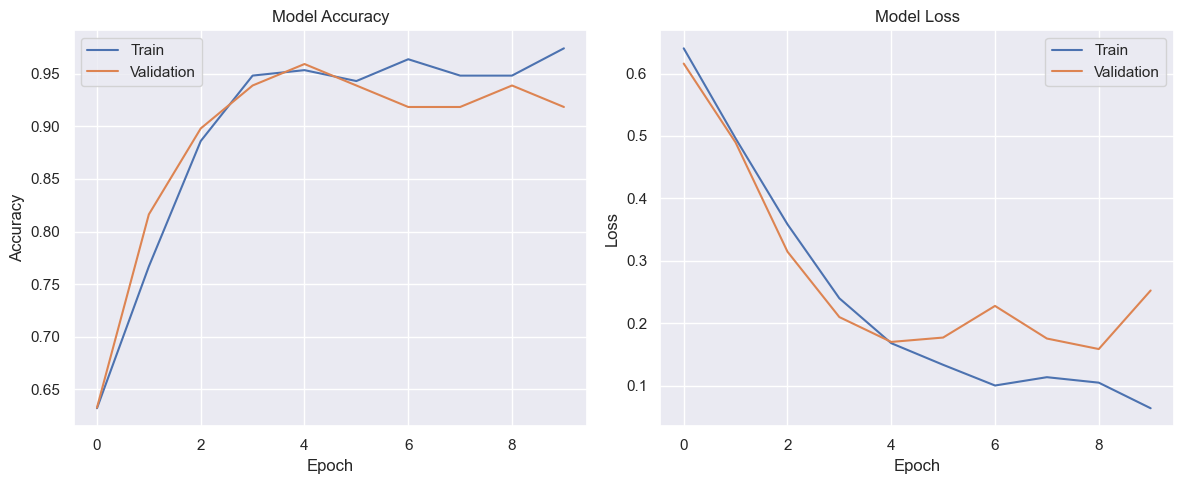

4/4 [==============================] - 0s 2ms/step


In [193]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelBinarizer

# Assuming 'history' is the output from CNN.fit()
# Plot training & validation accuracy values
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'])

plt.tight_layout()
plt.show()

# Make predictions
y_pred = CNN.predict(xtest1)
y_pred_classes = (y_pred > 0.5).astype("int32")

4/4 [==============================] - 0s 1ms/step


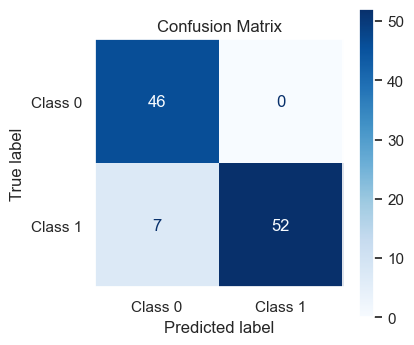

In [200]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Assuming y_pred_probs and ytest are defined and hold the model predictions and true labels
y_pred_probs = CNN.predict(xtest1)
y_pred = (y_pred_probs > 0.5).astype(int).flatten()  # Convert probabilities to binary class labels

# Compute confusion matrix
cm = confusion_matrix(ytest, y_pred)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Class 0', 'Class 1'])
disp.plot(cmap=plt.cm.Blues)

# Remove the grid
plt.grid(False)

# Set title and show the plot
plt.title('Confusion Matrix')
plt.show()


## LSTM

In [195]:
from tensorflow.keras.layers import LSTM, Dense

In [196]:
# Define the LSTM model
lstm = Sequential()

# Add LSTM layers
lstm.add(LSTM(50, return_sequences=True, input_shape=(xtrain1.shape[1], xtrain1.shape[2])))
lstm.add(LSTM(50, return_sequences=False))

# Add Dense layers
lstm.add(Dense(64, activation='relu'))
lstm.add(Dense(1, activation='sigmoid'))  # Use 'softmax' if you have multiple classes

# Compile the model
lstm.compile(optimizer=Adam(learning_rate=0.001),
              loss='binary_crossentropy',  # Use 'sparse_categorical_crossentropy' for multiple classes
              metrics=['accuracy'])

# Train the model
history = lstm.fit(xtrain1, ytrain, epochs=10, batch_size=32, validation_split=0.2)


Epoch 1/10
7/7 [==============================] - 4s 133ms/step - loss: 0.6842 - accuracy: 0.6580 - val_loss: 0.6497 - val_accuracy: 0.8776
Epoch 2/10
7/7 [==============================] - 0s 20ms/step - loss: 0.6196 - accuracy: 0.8394 - val_loss: 0.4751 - val_accuracy: 0.8980
Epoch 3/10
7/7 [==============================] - 0s 20ms/step - loss: 0.4006 - accuracy: 0.9275 - val_loss: 0.1765 - val_accuracy: 0.9592
Epoch 4/10
7/7 [==============================] - 0s 19ms/step - loss: 0.1448 - accuracy: 0.9482 - val_loss: 0.3005 - val_accuracy: 0.8980
Epoch 5/10
7/7 [==============================] - 0s 20ms/step - loss: 0.1374 - accuracy: 0.9482 - val_loss: 0.3624 - val_accuracy: 0.9184
Epoch 6/10
7/7 [==============================] - 0s 17ms/step - loss: 0.1385 - accuracy: 0.9585 - val_loss: 0.2551 - val_accuracy: 0.9184
Epoch 7/10
7/7 [==============================] - 0s 18ms/step - loss: 0.1189 - accuracy: 0.9585 - val_loss: 0.1830 - val_accuracy: 0.9184
Epoch 8/10
7/7 [==========

In [197]:
test_loss, test_accuracy = lstm.evaluate(xtest1, ytest)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

4/4 [==============================] - 0s 6ms/step - loss: 0.1737 - accuracy: 0.9333
Test Loss: 0.1737
Test Accuracy: 0.9333


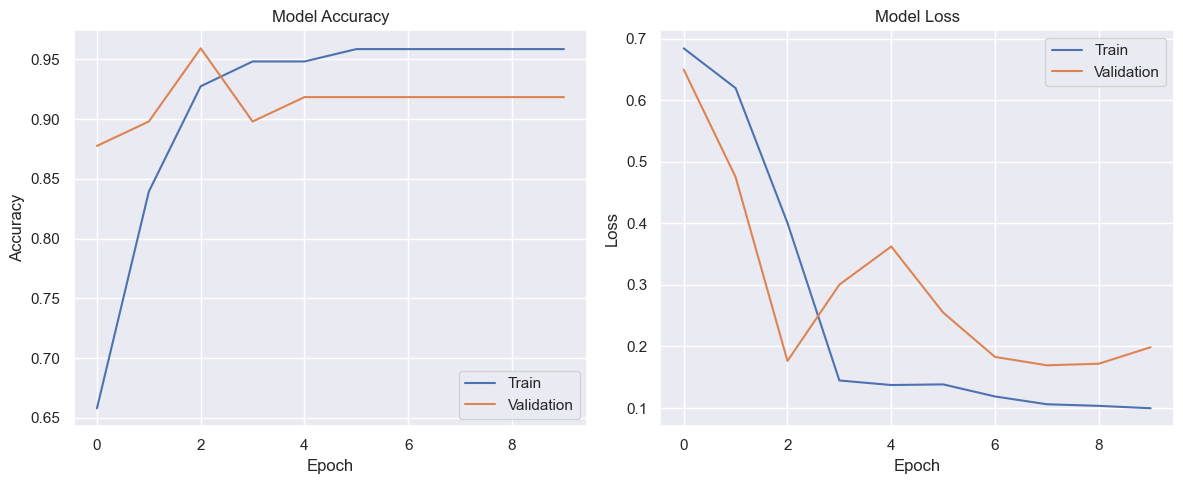

4/4 [==============================] - 1s 5ms/step


In [198]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'])

plt.tight_layout()
plt.show()

# Make predictions
y_pred = lstm.predict(xtest1)
y_pred_classes = (y_pred > 0.5).astype("int32")

4/4 [==============================] - 0s 5ms/step


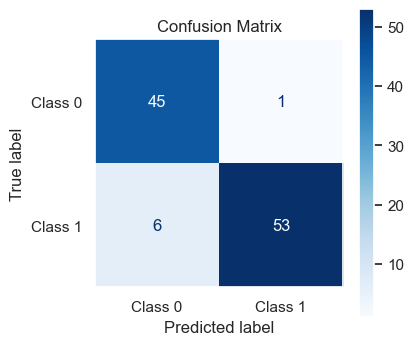

In [199]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Assuming y_pred_probs and ytest are defined and hold the model predictions and true labels
y_pred_probs = lstm.predict(xtest1)
y_pred = (y_pred_probs > 0.5).astype(int).flatten()  # Convert probabilities to binary class labels

# Compute confusion matrix
cm = confusion_matrix(ytest, y_pred)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Class 0', 'Class 1'])
disp.plot(cmap=plt.cm.Blues)

# Remove the grid
plt.grid(False)

# Set title and show the plot
plt.title('Confusion Matrix')
plt.show()


In [2]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Function to label encode all categorical columns
def label_encode_excel(input_file, output_file):
    # Load the Excel file
    df = pd.read_excel(input_file)
    
    # Initialize LabelEncoder
    label_encoder = LabelEncoder()

    # Loop through all columns
    for column in df.columns:
        # Check if the column has any non-numeric types (string/object columns)
        if df[column].dtype == 'object':
            # If so, convert all the column values to string to ensure uniformity
            df[column] = df[column].astype(str)
            # Now apply label encoding
            df[column] = label_encoder.fit_transform(df[column])
    
    # Save the modified DataFrame to a new Excel file
    df.to_excel(output_file, index=False)
    print(f"Label encoded data saved to {output_file}")

# Example usage
input_file = 'Autism child data.xlsx'  # Path to your input Excel file
output_file = 'encoded_data.xlsx'  # Path to save the label encoded Excel file

label_encode_excel(input_file, output_file)


Label encoded data saved to encoded_data.xlsx
